In [26]:
%pip install matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 15.8 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 25.3 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 22.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 31.8 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [seaborn]m7/8 [seaborn]ib]
Note: you may need to restart the kernel to use updated packages.


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 36.5 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 39.6 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np

In [16]:
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('course_lead_scoring_2026.csv')

In [3]:
print(df.shape)
print(df.dtypes)
df.head()

(5000, 9)
lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
print(df.isnull().sum())

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [5]:
categorical = df.select_dtypes(include='object').columns.tolist()
numerical = df.select_dtypes(exclude='object').columns.tolist()

/tmp/ipykernel_3975/3910409115.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include='object').columns.tolist()


In [6]:
if 'converted' in numerical:
    numerical.remove('converted')

In [7]:
print('Categóricas:', categorical)
print('Numéricas:', numerical)

Categóricas: ['lead_source', 'industry', 'employment_status', 'location']
Numéricas: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


In [8]:
df[categorical] = df[categorical].fillna('NA')

In [9]:
df[numerical] = df[numerical].fillna(0.0)

In [10]:
print(df.isnull().sum())

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


In [11]:
print(df['industry'].value_counts())

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64


In [12]:
print('Moda:', df['industry'].mode()[0])

Moda: technology


In [17]:
numerical = df.select_dtypes(exclude='object').columns.tolist()
numerical.remove('converted')

In [18]:
corr = df[numerical].corr()
print(corr)

                          annual_income  number_of_courses_viewed  \
annual_income                  1.000000                  0.161300   
number_of_courses_viewed       0.161300                  1.000000   
interaction_count              0.122842                  0.721609   
lead_score                     0.229496                  0.757204   

                          interaction_count  lead_score  
annual_income                      0.122842    0.229496  
number_of_courses_viewed           0.721609    0.757204  
interaction_count                  1.000000    0.915746  
lead_score                         0.915746    1.000000  


In [19]:
pairs = [
    ('interaction_count', 'lead_score'),
    ('number_of_courses_viewed', 'lead_score'),
    ('number_of_courses_viewed', 'interaction_count'),
    ('annual_income', 'interaction_count'),
]

for a, b in pairs:
    print(f'{a} x {b}: {corr.loc[a, b]:.4f}')

interaction_count x lead_score: 0.9157
number_of_courses_viewed x lead_score: 0.7572
number_of_courses_viewed x interaction_count: 0.7216
annual_income x interaction_count: 0.1228


In [20]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [21]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [22]:
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

In [23]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [24]:
print(len(df_train), len(df_val), len(df_test))

3000 1000 1000


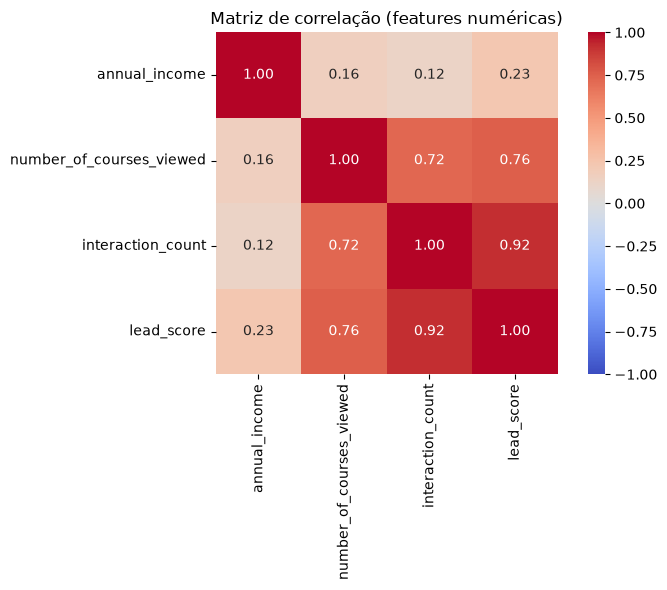

In [28]:

numerical = df.select_dtypes(exclude='object').columns.tolist()
numerical.remove('converted')

corr = df[numerical].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,        # mostra o valor em cada célula
    fmt='.2f',         # 2 casas decimais
    cmap='coolwarm',
    vmin=-1, vmax=1,   # escala fixa de -1 a 1
    square=True,
)
plt.title('Matriz de correlação (features numéricas)')
plt.tight_layout()
plt.savefig('correlation_matrix.png', dpi=150)  # salva a imagem
plt.show()

In [29]:
from sklearn.metrics import mutual_info_score

categorical = ['industry', 'location', 'lead_source', 'employment_status']

def mutual_info_converted(series):
    return mutual_info_score(series, y_train)

mi = df_train[categorical].apply(mutual_info_converted)
mi = mi.round(2).sort_values(ascending=False)
print(mi)

lead_source          0.03
employment_status    0.02
location             0.00
industry             0.00
dtype: float64


In [30]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

categorical = ['industry', 'location', 'lead_source', 'employment_status']
numerical = ['number_of_courses_viewed', 'annual_income',
             'interaction_count', 'lead_score']

features = categorical + numerical

# One-hot encoding (ajusta só no treino)
dv = DictVectorizer(sparse=False)

train_dict = df_train[features].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[features].to_dict(orient='records')
X_val = dv.transform(val_dict)

# Treino
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# Acurácia na validação
y_pred = model.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)
print(round(accuracy, 2))

0.65


In [31]:
def train_and_score(features):
    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(df_train[features].to_dict(orient='records'))
    X_vl = dv.transform(df_val[features].to_dict(orient='records'))

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    model.fit(X_tr, y_train)
    return accuracy_score(y_val, model.predict(X_vl))

# Acurácia original (sem arredondar)
original = train_and_score(features)
print('Original:', original)

# Removendo uma feature por vez
results = []
for f in features:
    reduced = [x for x in features if x != f]
    acc = train_and_score(reduced)
    results.append((f, acc, original - acc))

diff_df = pd.DataFrame(results, columns=['feature_removida', 'acuracia', 'diferenca'])
print(diff_df.sort_values('diferenca'))

# Só as três opções do quiz
options = ['lead_source', 'number_of_courses_viewed', 'interaction_count']
print(diff_df[diff_df['feature_removida'].isin(options)].sort_values('diferenca'))

Original: 0.645
           feature_removida  acuracia  diferenca
5             annual_income     0.724     -0.079
0                  industry     0.645      0.000
3         employment_status     0.645      0.000
1                  location     0.645      0.000
7                lead_score     0.644      0.001
4  number_of_courses_viewed     0.643      0.002
2               lead_source     0.642      0.003
6         interaction_count     0.601      0.044
           feature_removida  acuracia  diferenca
4  number_of_courses_viewed     0.643      0.002
2               lead_source     0.642      0.003
6         interaction_count     0.601      0.044


In [32]:

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

results = {}
for C in [0.000001, 0.00001, 0.0001, 0.001]:
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    acc = accuracy_score(y_val, model.predict(X_val))
    results[C] = round(acc, 3)
    print(f'C={C}: {results[C]}')

best_acc = max(results.values())
best_C = min(C for C, acc in results.items() if acc == best_acc)
print('Melhor C:', best_C, '| acurácia:', best_acc)

C=1e-06: 0.598
C=1e-05: 0.598
C=0.0001: 0.613
C=0.001: 0.645
Melhor C: 0.001 | acurácia: 0.645
